# Preprocesamiento y aumento de datos

En este capítulo fijamos cómo llega cada imagen a los modelos: normalización, resolución, objetivos de entrenamiento y *augmentation*. Cada decisión se apoya en una medición del EDA o en una comparación hecha aquí. Los insumos los generan `python scripts/eda.py seg` y `python scripts/figs_prep_seg.py`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from project.book_utils import CELL_COLORS, CELL_NAMES, need, pct, style

style()
pd.set_option("display.precision", 3)
TYPES = ["shsy5y", "astro", "cort"]

## Normalización

El enunciado propone como referencia dividir entre 255 y pide comparar con la normalización por percentiles por imagen y con los estadísticos del entrenamiento. Comparamos las tres sobre las 421 imágenes de entrenamiento. Medimos la desviación estándar de la imagen normalizada (el contraste que recibe la red) y su variación entre imágenes (rango intercuartílico).

In [2]:
nz = need("eda/seg/normalization.pkl")
S = nz["summary"].copy()
S["tipo"] = S.cell_type.map(CELL_NAMES)
S["DE relativa entre imágenes"] = S.std_iqr / S.std_med
S.pivot(index="norm", columns="tipo", values=["std_med", "DE relativa entre imágenes"]).round(3)

std_med                     \
tipo                        Astrocitos Corticales SH-SY5Y   
norm                                                        
media y DE de entrenamiento      0.604      1.101   1.015   
percentiles 1–99 por imagen      0.109      0.134   0.143   
÷ 255                            0.033      0.059   0.055   

                            DE relativa entre imágenes                     
tipo                                        Astrocitos Corticales SH-SY5Y  
norm                                                                       
media y DE de entrenamiento                      0.356      0.244   0.186  
percentiles 1–99 por imagen                      0.114      0.153   0.101  
÷ 255                                            0.356      0.244   0.186

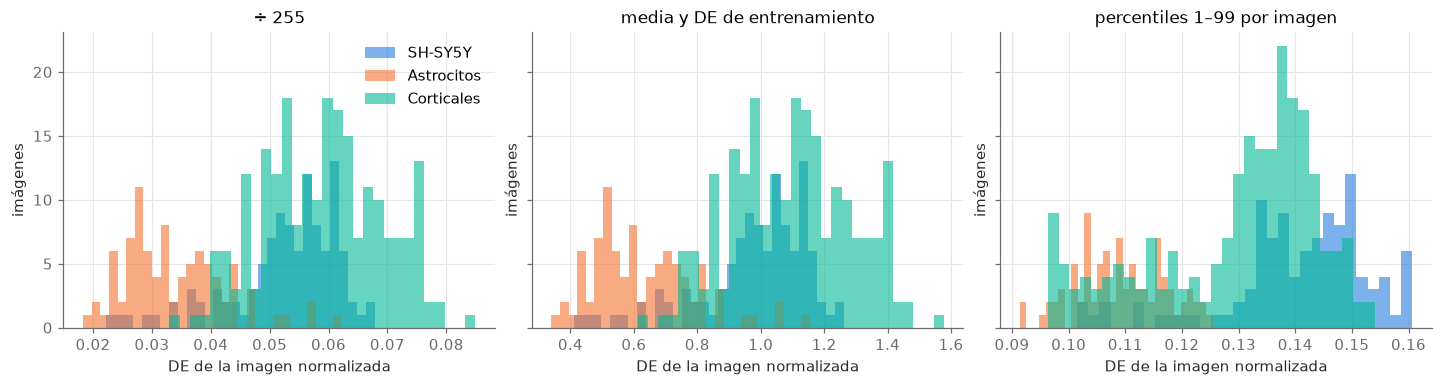

In [3]:
d = nz["per_image"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, norm in zip(axes, ["÷ 255", "media y DE de entrenamiento", "percentiles 1–99 por imagen"]):
    for t in TYPES:
        x = d[(d.norm == norm) & (d.cell_type == t)]["std"]
        ax.hist(x, bins=30, alpha=0.6, color=CELL_COLORS[t], label=CELL_NAMES[t])
    ax.set(title=norm, xlabel="DE de la imagen normalizada", ylabel="imágenes")
axes[0].legend()
plt.show()

In [4]:
r = lambda n, t: S[(S.norm == n) & (S.cell_type == t)].iloc[0]  # noqa: E731
ratio255 = r("÷ 255", "cort").std_med / r("÷ 255", "astro").std_med
ratiop = r("percentiles 1–99 por imagen", "cort").std_med / r("percentiles 1–99 por imagen", "astro").std_med
display(Markdown(
    f"Al dividir entre 255, la DE mediana de las imágenes de corticales es {ratio255:.2f} veces la de los astrocitos: el contraste "
    f"depende del tipo celular. Normalizar con la media y la DE del entrenamiento solo cambia la escala y conserva esa razón. "
    f"Con percentiles por imagen la razón baja a {ratiop:.2f}, y la variación relativa de la DE entre imágenes pasa de "
    f"{S[S.norm == '÷ 255']['DE relativa entre imágenes'].min():.2f}–{S[S.norm == '÷ 255']['DE relativa entre imágenes'].max():.2f} "
    f"a {S[S.norm.str.startswith('percentiles')]['DE relativa entre imágenes'].min():.2f}–"
    f"{S[S.norm.str.startswith('percentiles')]['DE relativa entre imágenes'].max():.2f}."))

Al dividir entre 255, la DE mediana de las imágenes de corticales es 1.82 veces la de los astrocitos: el contraste depende del tipo celular. Normalizar con la media y la DE del entrenamiento solo cambia la escala y conserva esa razón. Con percentiles por imagen la razón baja a 1.23, y la variación relativa de la DE entre imágenes pasa de 0.19–0.36 a 0.10–0.15.

Elegimos la **normalización por percentiles 1–99 por imagen** para todos los modelos. Iguala el contraste entre tipos celulares y entre placas sin depender de estadísticos globales, y con ella una imagen nueva se normaliza sin conocer el conjunto de entrenamiento, que es lo que ocurre en producción. Su condición de validez es que cada imagen contenga fondo y células: en una imagen casi vacía, los percentiles 1 y 99 quedan muy próximos y la normalización amplifica el ruido. En Sartorius toda imagen tiene al menos una célula anotada.

Esta comparación mide el efecto en la entrada, no en el AP. La ablación de normalización con reentrenamiento quedó fuera del presupuesto de GPU (recorte 4 del pre-registro).

## Resolución

Reescalar las imágenes de 520 × 704 a un cuadrado pequeño elimina células. La tabla repite la medición del EDA: fracción de instancias que quedan por debajo de *N* píxeles de área tras reescalar el lado mayor al tamaño objetivo.

In [5]:
rl = need("eda/seg/rescale_loss.pkl")
rl.assign(tipo=rl.cell_type.map(CELL_NAMES)).pivot_table(index=["target", "min_pixels"], columns="tipo", values="frac_below").map(pct)

tipo              Astrocitos Corticales SH-SY5Y
target min_pixels                              
256    10              0.1 %      0.3 %   0.7 %
       20              0.6 %      3.2 %   7.3 %
       30              2.0 %     14.0 %  22.5 %
384    10              0.0 %      0.1 %   0.1 %
       20              0.1 %      0.2 %   0.4 %
       30              0.2 %      0.9 %   2.0 %
512    10              0.0 %      0.1 %   0.1 %
       20              0.0 %      0.1 %   0.1 %
       30              0.1 %      0.1 %   0.2 %
520    10              0.0 %      0.0 %   0.1 %
       20              0.0 %      0.1 %   0.1 %
       30              0.1 %      0.1 %   0.2 %

A 256 píxeles, el 7.3 % de las células SH-SY5Y queda por debajo de 20 píxeles de área, el tamaño a partir del cual el *watershed* y el filtro de tamaño mínimo las descartan. Por eso **trabajamos a resolución nativa**:

- **Entrenamiento:** recortes aleatorios de 256 × 256 a escala nativa (sin reescalar). Así cabe un lote de 8 en 8 GB de VRAM y cada recorte conserva el tamaño real de las células.
- **Inferencia:** imagen completa con relleno por reflexión hasta 544 × 704, múltiplo de 32 en las dos dimensiones, como exigen los cuatro submuestreos de la U-Net++. La predicción se recorta a 520 × 704.
- **Mask R-CNN:** torchvision reescala internamente el lado menor a 800 píxeles; las anclas de 12 a 192 píxeles están definidas sobre esa escala ampliada.

No usamos *tiling* con solape: la imagen completa cabe en memoria en inferencia, de modo que los bordes de mosaico no aportan nada y añadirían un paso de fusión.

## De RLE a objetivos de cada modelo

Las anotaciones llegan como RLE por instancia. Las decodificamos en orden de filas con índice 1 (validado en el capítulo {doc}`10_seg_eda`) y construimos un mapa de etiquetas por imagen, en el que la primera instancia prevalece en los solapes. Cada modelo recibe un objetivo distinto derivado de ese mismo mapa, como muestra la {numref}`fig-objetivos`:

- **U-Net++:** tres clases por píxel: fondo, interior y borde (2 píxeles hacia dentro del contorno de cada célula, incluidos los contactos). Funciones `three_class_target` y `boundary_map` de `src/project/sartorius_data.py`.
- **Variante Hover:** probabilidad de célula y mapas H y V con la distancia horizontal y vertical al centroide de cada célula, normalizada a $[-1, 1]$ (`hv_maps`).
- **Mask R-CNN:** una caja y una máscara binaria por instancia.
- **Cellpose:** el propio paquete calcula los campos de flujo a partir del mapa de etiquetas.
- **SAM con *prompts*:** cajas, en inferencia, tomadas de Mask R-CNN.

```{figure} images/gen/seg_objetivos.png
:name: fig-objetivos
:width: 100%

*Objetivos de entrenamiento derivados del mismo mapa de etiquetas, en un recorte de 160 × 160 píxeles por tipo celular.* En el objetivo de la U-Net++ el azul es interior y el naranja, borde o contacto; en los mapas H y V el rojo es positivo y el azul, negativo. Imágenes de Sartorius {cite:p}`sartorius2021`; figura elaborada por los autores.
```

En el recorte de astrocitos, la anotación es un polígono de aristas rectas que no sigue las prolongaciones visibles en la imagen, y varias prolongaciones quedan como líneas de un píxel. Es el ruido de anotación descrito en el capítulo {doc}`10_seg_eda`: ningún modelo puede reproducir esas aristas, lo que acota el IoU alcanzable en astrocitos.

Los mapas H y V cambian de signo de forma brusca en el límite entre dos células vecinas. Ese salto es la señal que usa el post-proceso tipo HoVer-Net para separar células en contacto, que es justo el caso que el objetivo de 3 clases resuelve con la clase «borde».

## *Augmentation*

Usamos `albumentations` {cite:p}`buslaev2020albumentations`, que aplica la misma transformación geométrica a la imagen y a la máscara, con interpolación por vecino más próximo en la máscara. La configuración principal (`geo_photo_elastic`) combina:

| Tipo | Transformación | Probabilidad |
|---|---|---|
| Geométrica | Volteo horizontal y vertical; rotación de 90° | 0.5 cada una |
| Geométrica | Afín: escala 0.9–1.1 y rotación ±15° | 0.5 |
| Fotométrica | Brillo y contraste ±20 % | 0.5 |
| Fotométrica | Ruido gaussiano (DE 0.01–0.05) | 0.3 |
| Fotométrica | Desenfoque gaussiano (núcleo 3–5) | 0.2 |
| Elástica | Deformación elástica (α = 30, σ = 6) | 0.25 |

La escala se limita a ±10 % para no deshacer la decisión de resolución nativa: las células pequeñas siguen por encima del tamaño mínimo. La deformación elástica es moderada porque una deformación fuerte cambia la forma de los astrocitos más allá de lo que se observa en las imágenes reales. Mask R-CNN usa un subconjunto (volteos y brillo y contraste), porque sus máscaras por instancia se generan después de la transformación.

La {numref}`fig-aug` verifica la alineación: en siete aumentos aleatorios de la configuración principal superponemos el contorno de la máscara transformada sobre la imagen transformada. Los contornos siguen a las células en todos los casos, también tras la rotación afín, que rellena con negro las esquinas fuera de la imagen original.

```{figure} images/gen/seg_augmentation.png
:name: fig-aug
:width: 100%

*Verificación de alineación entre imagen y máscara tras el aumento de datos.* Imagen original y siete aumentos aleatorios de la misma imagen; los contornos naranjas son la máscara transformada. Imágenes de Sartorius {cite:p}`sartorius2021`; figura elaborada por los autores.
```

## Resumen de decisiones

| Paso | Decisión | Evidencia |
|---|---|---|
| Normalización | Percentiles 1–99 por imagen | Iguala el contraste entre tipos celulares (tabla de normalización) |
| Resolución | Nativa: recortes de 256 en entrenamiento, imagen completa con relleno a 544 × 704 en inferencia | A 256 píxeles se pierde el 7.3 % de las células SH-SY5Y |
| Objetivo de U-Net++ | 3 clases con borde de 2 píxeles | El 73 % de las células toca a otra (capítulo {doc}`10_seg_eda`) |
| *Augmentation* | Geométrica, fotométrica y elástica moderada | Alineación verificada en la {numref}`fig-aug`; las ablaciones del capítulo {doc}`14_seg_ablaciones_robustez` usan esta misma configuración |

La ablación completa de resolución × normalización × *augmentation* que pide el enunciado no se ejecutó (recorte 4 del pre-registro). Las decisiones de esta tabla valen, por tanto, como elecciones justificadas por mediciones sobre los datos, no como óptimos demostrados con reentrenamiento.